In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-09-21 17:32:15.932392: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
import importlib
import DAE_DataGenerator

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_optDG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from dataset_utils import add_noise
import math


In [4]:
import models
importlib.reload(models)
from models import *
# from models import CreateAutoEncoder, CreateSQAutoEncoder


weights_path = './SQ_DAE/model-f255d673-SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856-checkpoints/'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")

model = CreateSQAE_MaxConv2DReg_fromweights((16,16,2), weights_path, FEBits = 2, OutBits = 2, n_filters=5, pool_size=3, 
                        conv_kernel_size=3, decoder_filters = 128)
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)


Loading model from ./SQ_DAE/model-f255d673-SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856-checkpoints/weights.716-t206067.9531-v204930.4844.hdf5
Loading model from ./SQ_DAE/model-f255d673-SQDAE_Conv2D_Categorical_2bit_240eN_Target_0_30_856-checkpoints/weights.716-t206067.9531-v204930.4844.hdf5
index: 0 input_2
index: 1 soft_quantizer_output
index: 2 q_separable_conv2d_1
index: 3 q_activation_6
index: 4 q_conv2d_1
index: 5 q_activation_7
index: 6 average_pooling2d_1
index: 7 q_activation_8
index: 8 conv2d_transpose_2
index: 9 q_activation_9
index: 10 conv2d_transpose_3
index: 11 q_activation_10
index: 12 conv2d_1
index: 13 q_activation_11
index: 14 flatten_1
index: 15 dense_1
index: 16 reshape_1
latent space layer:  q_activation_8 (None, 4, 4, 5)
Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 16, 16, 2)]       0         
                        

In [9]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

# dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
# dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')


# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3sr_16x16_80eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3sr_16x16_80eN_raw')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3srCI_16x16_120eN_raw')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3srCI_16x16_120eN_raw')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [10]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    select_contained = True,
    log_compression = False,
    noise = [0, 120], #[mean, sigma]
    min_threshold = None,
    max_threshold = None,
    
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    log_compression = False,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0, 120],
    # threshold = -1,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:04<00:00,  4.20it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_120eN_raw is removed...


Saving batches as TFRecords: 100%|██████████| 21/21 [00:10<00:00,  2.08it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_120eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_120eN_raw/metadata.json


--- Validation generator 15.703046083450317 seconds ---


Processing Files...: 100%|██████████| 80/80 [00:18<00:00,  4.37it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_120eN_raw is removed...


Saving batches as TFRecords: 100%|██████████| 84/84 [00:43<00:00,  1.95it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_120eN_raw/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_120eN_raw/metadata.json


--- Training generator 63.19181942939758 seconds ---


In [6]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_240eN_raw/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_240eN_raw/metadata.json


tf.Tensor([ 0.24462697  0.5311168   0.81872827 -0.5624242 ], shape=(4,), dtype=float32)
max: 24136.25
min: -3671.358


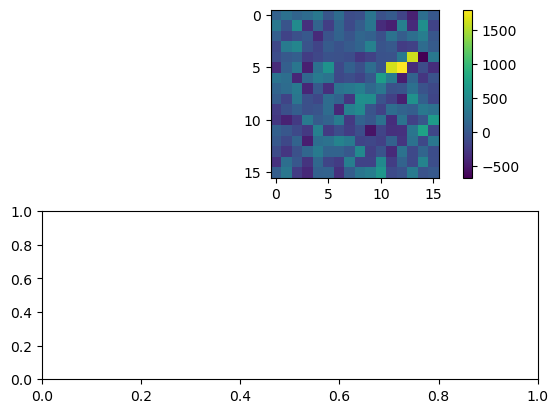

In [7]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=50

cluster = training_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1][n])
cluster=cluster[0][:,:,:,0]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [8]:
from datetime import datetime
tname = 'SQDAE_MaxConv2Dregression_Categorical2bit_240eN_Target_0_30_856'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE_regression/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'
print(fingerprint)

ac3e95e5


In [9]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 500

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [10]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=4000,
        shuffle=False,
        verbose=1
    )

Epoch 1/4000
 2/84 [..............................] - ETA: 8s - loss: 103645.0312  

2026-07-07 02:49:33.027990: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-07-07 02:49:33.039435: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800
2026-07-07 02:49:33.060289: I tensorflow/core/util/cuda_solvers.cc:179] Creating GpuSolver handles for stream 0x556fd1d5c510


84/84 [==============================] - ETA: 0s - loss: 103034.1875
Epoch 1: val_loss improved from inf to 102730.69531, saving model to ./SQ_DAE_regression/model-ac3e95e5-SQDAE_MaxConv2Dregression_Categorical2bit_240eN_Target_0_30_856-checkpoints/weights.01-t103034.19-v102730.70.hdf5
84/84 [==============================] - 16s 169ms/step - loss: 103034.1875 - val_loss: 102730.6953
Epoch 2/4000
84/84 [==============================] - ETA: 0s - loss: 31327.5352
Epoch 2: val_loss improved from 102730.69531 to 10103.00781, saving model to ./SQ_DAE_regression/model-ac3e95e5-SQDAE_MaxConv2Dregression_Categorical2bit_240eN_Target_0_30_856-checkpoints/weights.02-t31327.54-v10103.01.hdf5
84/84 [==============================] - 8s 98ms/step - loss: 31327.5352 - val_loss: 10103.0078
Epoch 3/4000
84/84 [==============================] - ETA: 0s - loss: 7866.1279
Epoch 3: val_loss improved from 10103.00781 to 5522.36377, saving model to ./SQ_DAE_regression/model-ac3e95e5-SQDAE_MaxConv2Dregress

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)




Epoch 1691: val_loss did not improve from -22247.48242
84/84 [==============================] - 6s 77ms/step - loss: -20981.0938 - val_loss: -20126.0566
Epoch 1692/4000
84/84 [==============================] - ETA: 0s - loss: -20610.5195
Epoch 1692: val_loss did not improve from -22247.48242
84/84 [==============================] - 7s 78ms/step - loss: -20610.5195 - val_loss: -20783.8105
Epoch 1693/4000
84/84 [==============================] - ETA: 0s - loss: -20708.1191
Epoch 1693: val_loss did not improve from -22247.48242
84/84 [==============================] - 7s 78ms/step - loss: -20708.1191 - val_loss: -21779.2461
Epoch 1694/4000
84/84 [==============================] - ETA: 0s - loss: -20687.6113
Epoch 1694: val_loss did not improve from -22247.48242
84/84 [==============================] - 7s 78ms/step - loss: -20687.6113 - val_loss: -21378.5469
Epoch 1695/4000
84/84 [==============================] - ETA: 0s - loss: -20936.3672
Epoch 1695: val_loss did not improve from -2224

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

